# Training data exploration

Inspect the **training partition only**. These aggregates and figures are produced by `creditguard.eda` during CLI training. No customer rows are displayed. The CSV technical index is excluded. Run this notebook after `python -m creditguard.train --profile full`.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
METRICS = ROOT / "reports" / "metrics"
FIGURES = ROOT / "reports" / "figures"
assert (METRICS / "final_test_metrics.json").exists(), "Run the full training CLI first."


def read_json(name):
    return json.loads((METRICS / name).read_text())


def show_figure(name):
    display(Image(filename=str(FIGURES / name)))

In [2]:
overview = read_json("training_eda.json")
split = read_json("split_summary.json")
display(pd.Series(overview).to_frame("Training observation"))
display(pd.DataFrame(split["partitions"]).T)

,Training observation
partition,train
n_records,89975
n_features,10
positive_rate,0.066819
dtypes,{'RevolvingUtilizationOfUnsecuredLines': 'floa...
missing,"{'RevolvingUtilizationOfUnsecuredLines': 0, 'a..."
duplicate_feature_rows,363
conflicting_feature_groups,21
zero_age,0
utilization_above_one,1994


,n_records,positive_rate
train,89975.0,0.066819
selection,22499.0,0.067070
calibration,15018.0,0.066853
threshold,7508.0,0.066596
test,15000.0,0.066733


## Data quality and split safety

Exact feature duplicates are identified without the target or CSV index. All observations in a feature group, including conflicting labels, remain together. Stratification uses group-majority labels, so row proportions are approximate. The same grouping is used in training cross-validation.

In [3]:
display(pd.read_csv(METRICS / "training_descriptive_statistics.csv", index_col=0))
print(
    f"Dataset feature duplicates: {split['duplicate_feature_rows']}; "
    f"conflicting groups: {split['conflicting_feature_groups']}."
)

,count,mean,std,min,1%,50%,95%,99.5%,max
RevolvingUtilizationOfUnsecuredLines,89975.0,5.954622,207.073886,0.0,0.0,0.15376,1.0,1.34087,22198.0
age,89975.0,52.329458,14.764128,21.0,24.0,52.00000,78.0,89.00000,107.0
NumberOfTime30-59DaysPastDueNotWorse,89975.0,0.405001,4.006751,0.0,0.0,0.00000,2.0,5.00000,98.0
DebtRatio,89975.0,355.794952,2010.618462,0.0,0.0,0.36738,2475.0,6189.39000,326442.0
MonthlyIncome,72030.0,6715.301763,16489.010574,0.0,0.0,5400.00000,14660.0,35000.00000,3008750.0
NumberOfOpenCreditLinesAndLoans,89975.0,8.468719,5.157876,0.0,0.0,8.00000,18.0,27.00000,58.0
NumberOfTimes90DaysLate,89975.0,0.251181,3.982319,0.0,0.0,0.00000,1.0,4.00000,98.0
NumberRealEstateLoansOrLines,89975.0,1.020661,1.141648,0.0,0.0,1.00000,3.0,6.00000,54.0
NumberOfTime60-89DaysPastDueNotWorse,89975.0,0.224440,3.966875,0.0,0.0,0.00000,1.0,3.00000,98.0
NumberOfDependents,87656.0,0.757484,1.116624,0.0,0.0,0.00000,3.0,5.00000,20.0


Dataset feature duplicates: 646; conflicting groups: 37.


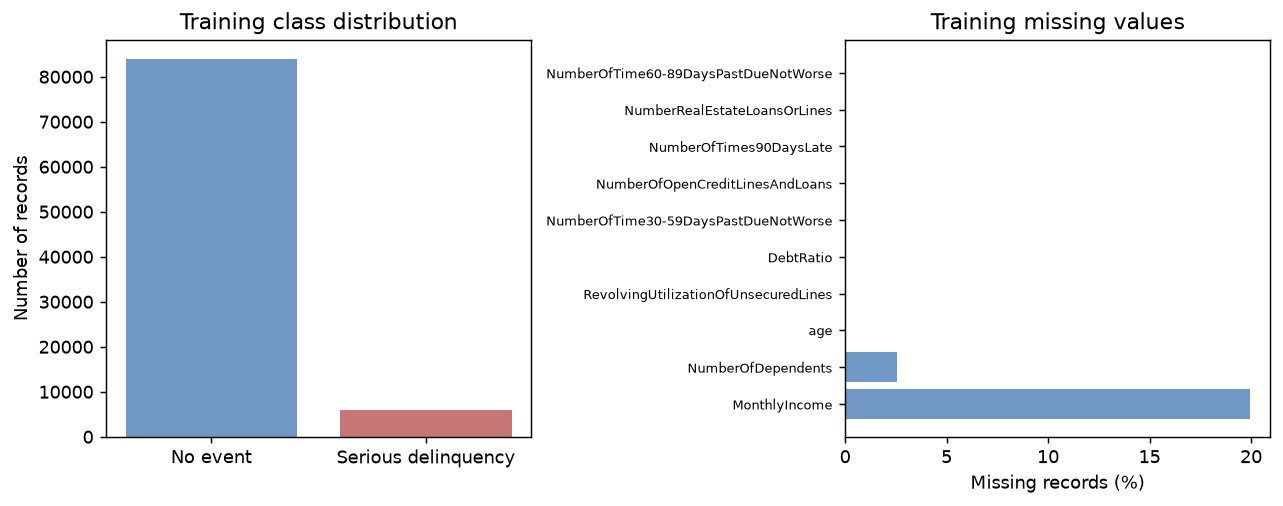

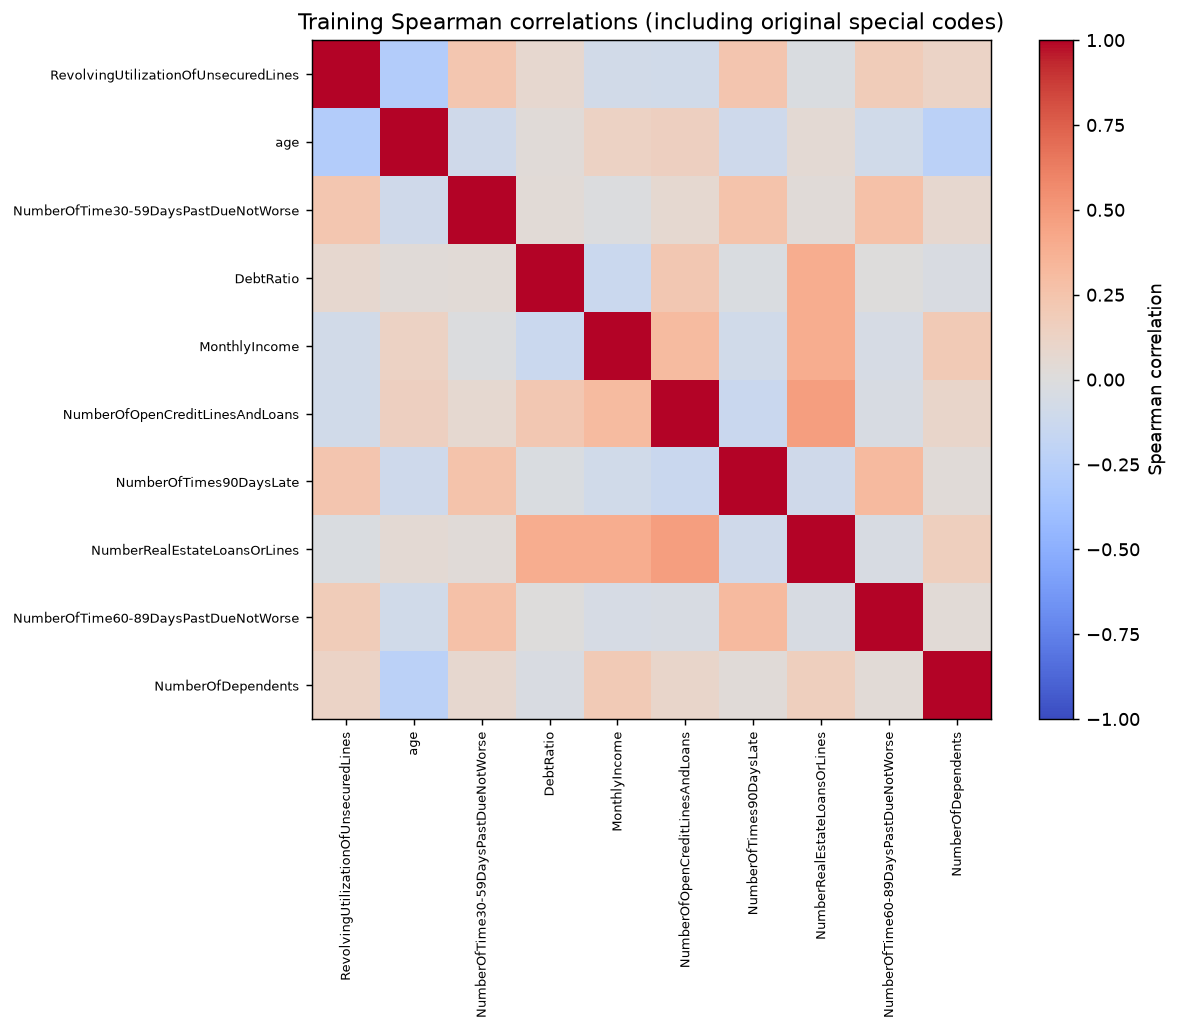

In [4]:
show_figure("eda_class_and_missing.png")
show_figure("eda_correlations.png")

## Distributions and relationship with the outcome

Income, debt ratio, and utilization use log(1 + value) axes to expose their tails without deleting rows. Conditional distributions compare the two target classes. Binned event rates complement correlations; they are descriptive associations.

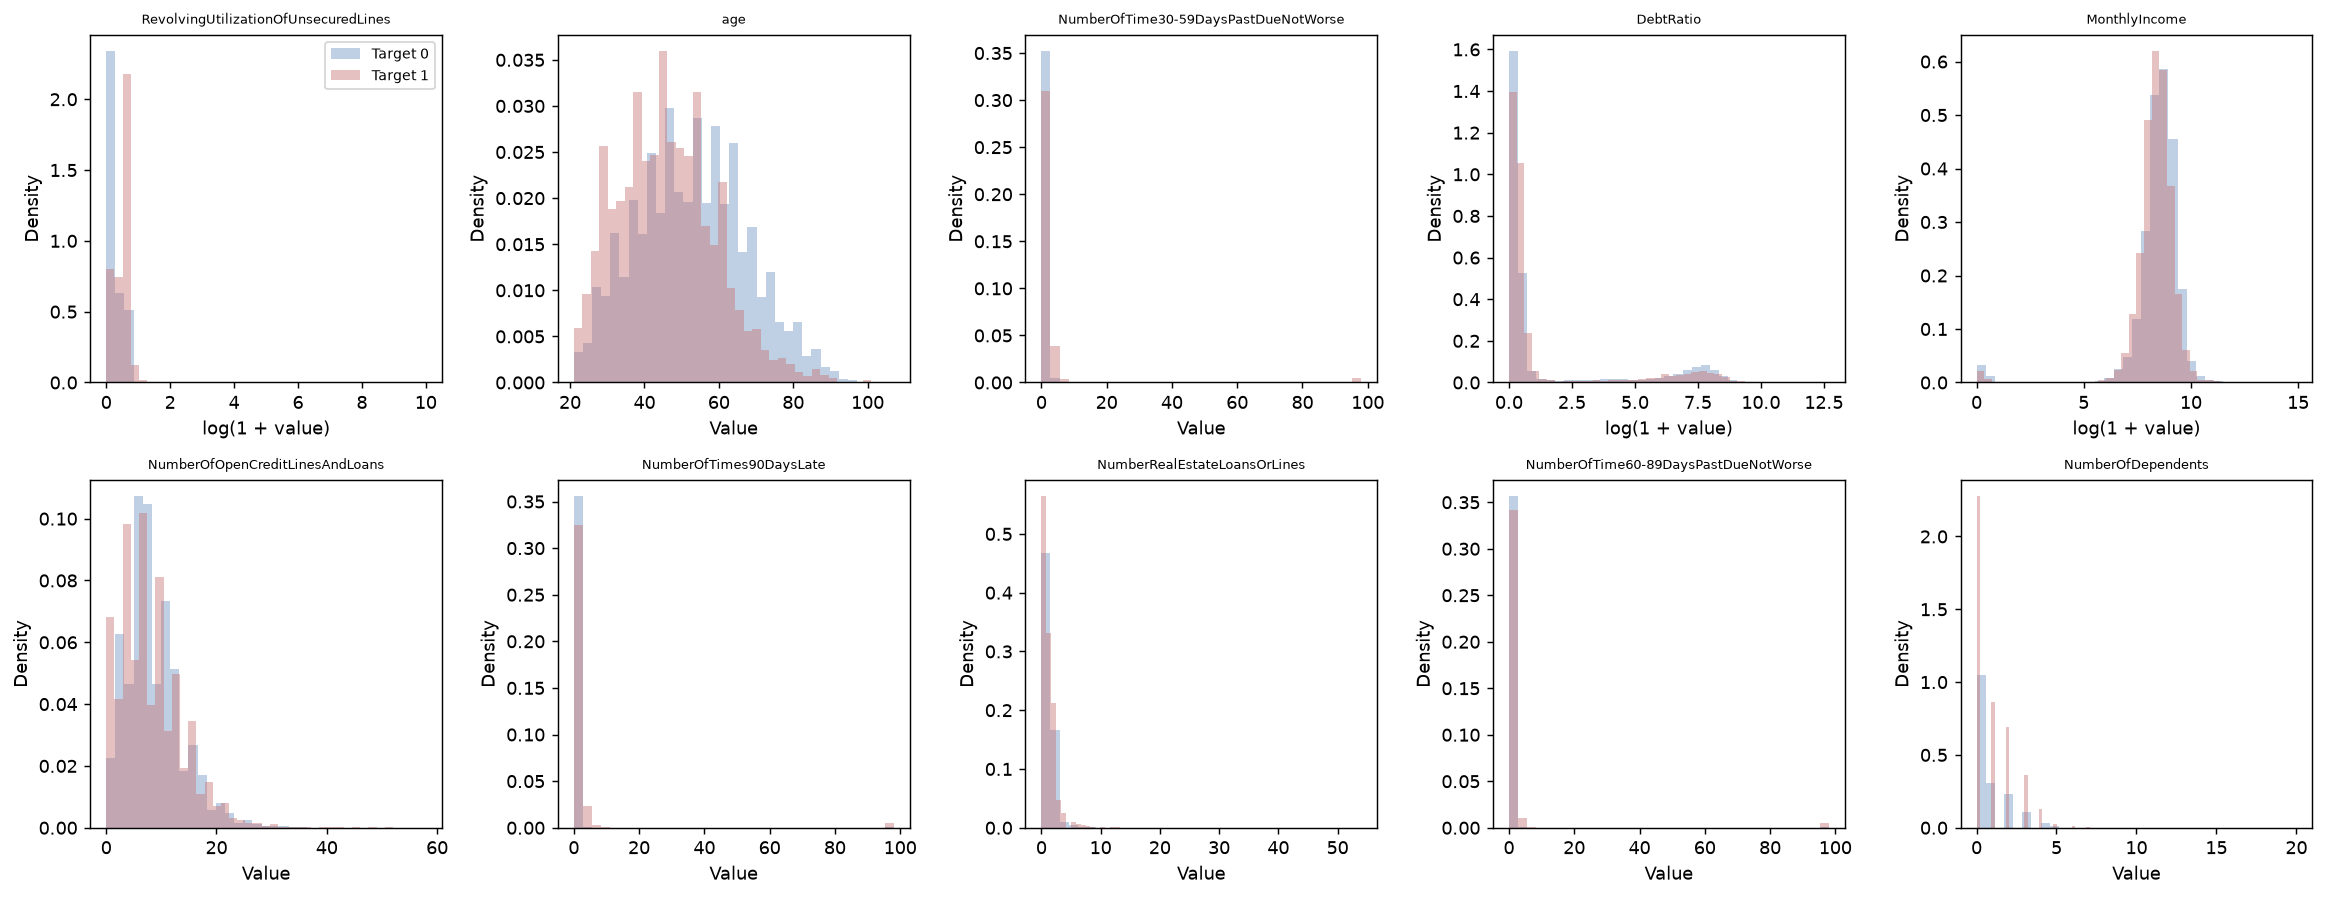

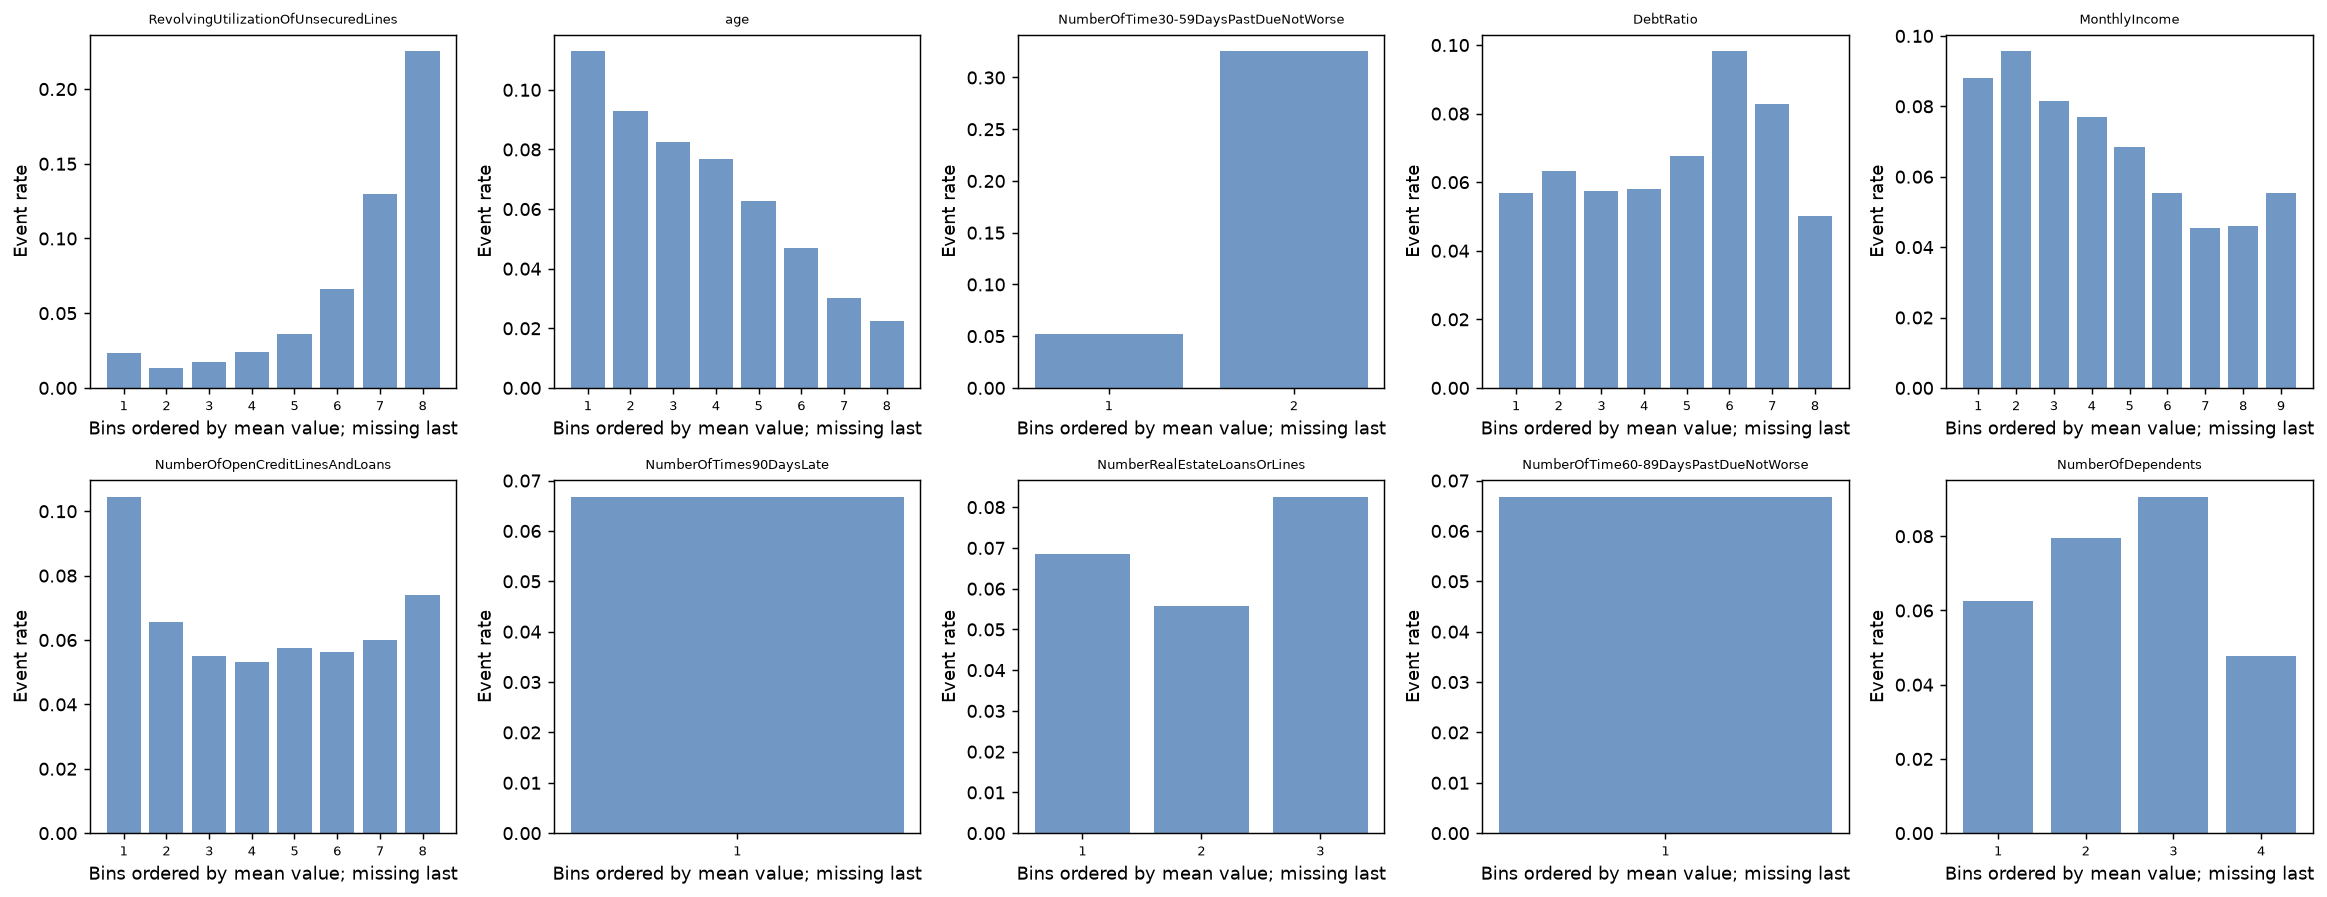

,feature,bin,n_records,event_rate
0,RevolvingUtilizationOfUnsecuredLines,"(-0.001, 0.00638]",11247,0.023117
1,RevolvingUtilizationOfUnsecuredLines,"(0.00638, 0.0297]",11247,0.013159
2,RevolvingUtilizationOfUnsecuredLines,"(0.0297, 0.0703]",11247,0.017338
3,RevolvingUtilizationOfUnsecuredLines,"(0.0703, 0.154]",11247,0.024006
4,RevolvingUtilizationOfUnsecuredLines,"(0.154, 0.307]",11246,0.036013
5,RevolvingUtilizationOfUnsecuredLines,"(0.307, 0.557]",11247,0.066151
6,RevolvingUtilizationOfUnsecuredLines,"(0.557, 0.924]",11247,0.129546
7,RevolvingUtilizationOfUnsecuredLines,"(0.924, 22198.0]",11247,0.225216
8,age,"(20.999, 34.0]",11433,0.112919
9,age,"(34.0, 41.0]",11356,0.092814


In [5]:
show_figure("eda_target_distributions.png")
show_figure("eda_feature_event_rates.png")
display(pd.read_csv(METRICS / "training_feature_event_rates.csv"))

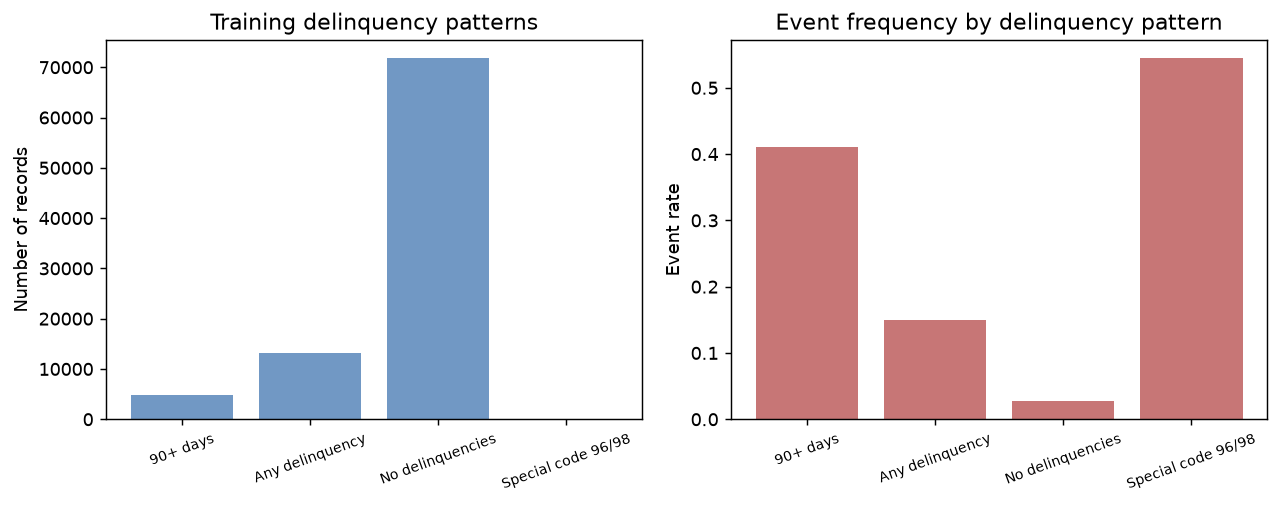

,pattern,size,mean
0,90+ days,4875,0.410256
1,Any delinquency,13214,0.149463
2,No delinquencies,71739,0.027279
3,Special code 96/98,147,0.544218


In [6]:
show_figure("eda_delinquency_patterns.png")
display(pd.read_csv(METRICS / "training_delinquency_patterns.csv"))

## Conclusions and preprocessing decisions

Income and dependents have missing values. Income, debt ratio, and utilization have long tails; utilization above 1 is retained. Values 96/98 co-occur in all three delinquency columns, separated from ordinary counts by a large gap. The supplied dictionary does not define their meaning. They are treated as unresolved values, not literal counts, with missing indicators or native tree missing handling and an engineered special-code flag. This is an explicit modeling assumption.

Logistic Regression uses training-only 99.5th-percentile clipping, median imputation, and scaling. Trees retain extreme numeric values; CatBoost uses native missing-value handling. Imputation and clipping are fitted within each CV training fold. The unobserved meaning of sentinel codes, historical data, and absence of timestamps remain limitations.

In [7]:
n = overview["n_records"]
print(f"Training: {n:,} records; event rate {overview['positive_rate']:.3%}.")
print(
    f"Missing income: {overview['missing']['MonthlyIncome'] / n:.2%}; "
    f"missing dependents: {overview['missing']['NumberOfDependents'] / n:.2%}."
)
print(
    f"Utilization > 1: {overview['utilization_above_one']:,}; "
    f"all-three special codes: {overview['all_three_codes_cooccur']:,}."
)

Training: 89,975 records; event rate 6.682%.
Missing income: 19.94%; missing dependents: 2.58%.
Utilization > 1: 1,994; all-three special codes: 147.
